# APS2 — Classificação: Adult Income Census

**Disciplina:** Machine Learning  
**Integrantes:** Vanessa Ricoy e Victor Cunha  
**Data de entrega:** 30/10/2026

## Objetivo

Na [APS1](https://vanessaricoy.github.io/aps1-adult-income/), exploramos a base Adult Income Census e vimos que escolaridade, ocupação e idade apresentam diferenças entre as faixas de renda. Agora queremos testar se essas informações, junto das outras variáveis do dataset, ajudam a **classificar a renda anual em `<=50K` ou `>50K`**.

Vamos retomar a limpeza e o pré-processamento da primeira entrega, comparar alguns classificadores e observar onde eles acertam e erram. No final, usamos o conjunto de teste, que ficou reservado na APS1, para avaliar o modelo escolhido. A ideia não é prever a renda exata de uma pessoa, mas distinguir as duas categorias da base.

## 1. Retomando a base da APS1

A variável `income` tem apenas duas categorias, então nosso problema é de **classificação**. Vamos usar `>50K` como classe positiva, isto é, a faixa que queremos identificar.

Na primeira entrega, encontramos valores `?`, o texto `occupation` no lugar de uma ocupação e linhas idênticas. Mantemos o mesmo tratamento para não mudar a base entre as duas etapas. Também seguimos com `education.num` no lugar de `education`, como decidimos ao preparar o primeiro pipeline.

Outro ponto importante é o desequilíbrio das classes: cerca de 76% do treino ficou em `<=50K`. Se o modelo prever sempre essa categoria, já terá uma acurácia aparentemente alta, mas deixará passar todos os casos de `>50K`. Por isso, além da acurácia, vamos olhar **precisão, recall, F1, ROC-AUC e AP**. A AP resume o comportamento da precisão à medida que tentamos recuperar mais registros da classe positiva.

Para escolher o modelo sem usar o teste antecipadamente, fazemos validação cruzada em parte do treino e deixamos outra parte para escolher o limiar de classificação. As transformações ficam dentro do pipeline, para serem aprendidas em cada divisão de treinamento.

In [1]:
# Bibliotecas para preparar os dados, treinar e comparar os modelos.
import sys, subprocess, warnings, os, glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score,
    recall_score, precision_recall_curve, roc_auc_score, roc_curve
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV, learning_curve
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

SEMENTE = 42
COR_PRINCIPAL = '#9E2A2B'
COR_SECUNDARIA = '#C65D47'
COR_DESTAQUE = '#5F0F40'
COR_NEUTRA = '#6C757D'
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
print('Python:', sys.version.split()[0])
print('scikit-learn:', __import__('sklearn').__version__)
print('Pandas:', pd.__version__)

# SHAP é usado na etapa de explicabilidade. No Colab ele costuma vir instalado.
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'shap'])
    import shap


Python: 3.12.6
scikit-learn: 1.9.1
Pandas: 3.1.0


/tmp/aps2deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# A variável de ambiente APS2_DATA_PATH (opcional) permite testar com um CSV local.
# No Colab, sem a variável, o dataset da APS1 é baixado automaticamente do Kaggle.
caminho_local = os.environ.get('APS2_DATA_PATH', '').strip()
if caminho_local:
    arquivo_csv = caminho_local
    origem = f'Arquivo local: {arquivo_csv}'
else:
    candidatos = [p for p in ['adult_income.csv', 'adult.csv'] if os.path.isfile(p)]
    if candidatos:
        arquivo_csv = candidatos[0]
        origem = f'Arquivo encontrado na pasta: {arquivo_csv}'
    else:
        try:
            import kagglehub
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
            import kagglehub
        pasta_dataset = kagglehub.dataset_download('anaghakp/adult-income-census')
        arquivos = sorted(glob.glob(os.path.join(pasta_dataset, '**', '*.csv'), recursive=True))
        if not arquivos:
            raise FileNotFoundError('O KaggleHub não retornou arquivos CSV. Verifique o dataset.')
        arquivo_csv = arquivos[0]
        origem = f'Kaggle: anaghakp/adult-income-census ({os.path.basename(arquivo_csv)})'

df = pd.read_csv(arquivo_csv)
df.columns = df.columns.str.strip()
colunas_aps1 = [
    'age','workclass','fnlwgt','education','education.num',
    'marital.status','occupation','relationship','race','sex',
    'native.country','income'
]
if set(df.columns) != set(colunas_aps1):
    raise ValueError(f'O CSV precisa conter as 12 colunas da APS1. Encontradas: {df.columns.tolist()}')
df = df[colunas_aps1].copy()
print('Origem:', origem)
print('Dimensões originais:', df.shape)
if len(df) != 31947:
    warnings.warn('A APS1 tinha 31.947 registros: confirme se a fonte ou versão mudou.')
display(df.head(3))

Origem: Arquivo local: /tmp/aps2data/adult income1.csv
Dimensões originais: (31947, 12)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,native.country,income
0,17,Private,148522,11th,7,Never-married,occupation,Own-child,White,Male,United-States,<=50K
1,17,Private,93235,12th,8,Never-married,occupation,Own-child,White,Female,United-States,<=50K
2,17,Private,184924,9th,5,Never-married,occupation,Own-child,White,Male,United-States,<=50K


In [3]:
# Exatamente as substituições e a exclusão de duplicados descritas na APS1.
df_limpo = df.copy()
for coluna in df_limpo.select_dtypes(include=['object', 'string']).columns:
    df_limpo[coluna] = df_limpo[coluna].astype('string').str.strip().replace('?', pd.NA)
df_limpo['occupation'] = df_limpo['occupation'].replace('occupation', pd.NA)
# Converter colunas categóricas para object com np.nan, visando compatibilidade com SimpleImputer.
for coluna in df_limpo.select_dtypes(include=['string']).columns:
    df_limpo[coluna] = df_limpo[coluna].astype(object).where(df_limpo[coluna].notna(), np.nan)

duplicatas = int(df_limpo.duplicated().sum())
df_limpo = df_limpo.drop_duplicates().copy()
assert not df_limpo['income'].isna().any(), 'Existem rótulos ausentes.'
assert set(df_limpo['income'].unique()) == {'<=50K', '>50K'}, 'Rótulos diferentes dos da APS1.'

X = df_limpo.drop(columns='income')
y = df_limpo['income'].map({'<=50K': 0, '>50K': 1}).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)
print('Duplicatas removidas:', duplicatas)
print('Linhas após limpeza:', len(df_limpo))
print('Treino original:', X_train.shape, '| Teste reservado:', X_test.shape)
print('Percentual >50K no treino: {:.2f}%'.format(y_train.mean()*100))
print('Ausências após limpeza:')
display(df_limpo.isna().sum().loc[lambda s: s > 0].to_frame('Quantidade'))

if len(df)==31947:
    assert len(df_limpo)==31882 and len(X_train)==25505 and len(X_test)==6377, 'A limpeza/divisão se afastou da APS1.'

Duplicatas removidas: 65
Linhas após limpeza: 31882
Treino original: (25505, 11) | Teste reservado: (6377, 11)
Percentual >50K no treino: 24.07%
Ausências após limpeza:


,Quantidade
workclass,1772
occupation,3240
native.country,25


### Resultado da limpeza

A tabela acima permite conferir os registros que precisaram de tratamento. Na APS1, encontramos **65 linhas repetidas** e ficamos com **31.882 registros** depois da limpeza. Mantemos essa referência para ter certeza de que a modelagem está usando a mesma base. Os valores sem ocupação informada continuam presentes, agora marcados como ausentes.

## 2. Separando os dados para os modelos

Na APS1, dividimos a base em **80% para treino e 20% para teste**. Vamos manter exatamente essa divisão. Do treino, reservamos mais 20% para validação e usamos o restante para comparar e ajustar os modelos.

Assim, temos três conjuntos: o de desenvolvimento, onde treinamos e comparamos as alternativas; o de validação, onde escolhemos o limiar da decisão; e o de teste, que só entra depois que essas escolhas estiverem prontas.

In [4]:
# Mantemos education.num, retirando a variável categórica redundante, conforme APS1.
X_train_modelo = X_train.drop(columns=['education']).copy()
X_test_modelo = X_test.drop(columns=['education']).copy()
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train_modelo, y_train, test_size=0.20, random_state=SEMENTE, stratify=y_train
)
resumo_splits = pd.DataFrame({
    'Conjunto':['Desenvolvimento (seleção e tuning)', 'Validação (limiar)', 'Teste final (reservado)'],
    'Linhas':[len(X_dev),len(X_val),len(X_test_modelo)],
    '% classe >50K':[round(y_dev.mean()*100,2), round(y_val.mean()*100,2),round(y_test.mean()*100,2)]
})
display(resumo_splits)
assert X_dev.index.intersection(X_val.index).empty
assert X_train_modelo.index.intersection(X_test_modelo.index).empty
assert X_val.index.intersection(X_test_modelo.index).empty

,Conjunto,Linhas,% classe >50K
0,Desenvolvimento (seleção e tuning),20404,24.06
1,Validação (limiar),5101,24.07
2,Teste final (reservado),6377,24.07


### Como ficaram os conjuntos

Com a mesma divisão da APS1, o teste continua com **6.377 registros**. Dos **25.505** registros de treino, **20.404** ficam para desenvolvimento e **5.101** para validação. A tabela também mostra a proporção de `>50K` em cada conjunto. Como a separação foi estratificada, esperamos percentuais próximos, sem perder a diferença natural entre as classes.

## 3. Preparação das variáveis

Na primeira entrega, organizamos as variáveis numéricas e categóricas com um `ColumnTransformer`. Vamos aproveitar essa ideia aqui, mas colocando o pré-processamento **dentro do pipeline de cada modelo**. Isso é importante na validação cruzada: o preenchimento de ausências e as escalas precisam ser aprendidos apenas com os dados usados para treinar cada divisão.

Nas colunas numéricas, usamos a mediana para ausências e o `RobustScaler`, que é menos sensível a valores extremos na definição da escala. Nas categóricas, preenchemos as ausências com `Ausente` e aplicamos one-hot encoding. Mantemos os registros que têm informações faltantes, sem tentar adivinhar suas categorias.

In [5]:
COLUNAS_NUMERICAS = ['age', 'fnlwgt', 'education.num']
COLUNAS_CATEGORICAS = [c for c in X_dev.columns if c not in COLUNAS_NUMERICAS]

def novo_onehot(agrupar_raras=False):
    argumentos = {
        'handle_unknown': 'infrequent_if_exist' if agrupar_raras else 'ignore'
    }
    if agrupar_raras:
        argumentos['min_frequency'] = 20
    try:
        return OneHotEncoder(**argumentos, sparse_output=False)
    except TypeError:
        return OneHotEncoder(**argumentos, sparse=False)

def criar_preprocessador(agrupar_raras=False):
    numericas = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', RobustScaler())
    ])
    categoricas = Pipeline([
        ('imputacao', SimpleImputer(strategy='constant', fill_value='Ausente')),
        ('onehot', novo_onehot(agrupar_raras=agrupar_raras))
    ])
    return ColumnTransformer([
        ('numericas', numericas, COLUNAS_NUMERICAS),
        ('categoricas', categoricas, COLUNAS_CATEGORICAS)
    ])

def criar_pipeline(modelo, agrupar_raras=False):
    return Pipeline([
        ('preprocessamento', criar_preprocessador(agrupar_raras)),
        ('modelo', modelo)
    ])

print('Variáveis numéricas:', COLUNAS_NUMERICAS)
print('Variáveis categóricas:', COLUNAS_CATEGORICAS)
print('Total de atributos originais:', X_dev.shape[1])


Variáveis numéricas: ['age', 'fnlwgt', 'education.num']
Variáveis categóricas: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Total de atributos originais: 10


### Variáveis usadas nos modelos

Depois de retirar `education`, mantivemos **10 colunas originais**. Três são numéricas (`age`, `fnlwgt` e `education.num`) e as outras são categóricas. O one-hot encoding aumenta o número de colunas durante o treinamento, mas preserva as categorias sem impor uma ordem numérica artificial. Ainda não temos um resultado de classificação nesta etapa: estamos só preparando as entradas.

## 4. Seleção dos modelos e dos hiperparâmetros

O enunciado pede pelo menos três alternativas: um modelo simples de referência, um modelo linear regularizado e um conjunto de árvores. Por isso, usamos o **Dummy**, a **regressão logística com regularização L2** e a **Random Forest**.

A classe `>50K` corresponde a aproximadamente 24% dos registros. Assim, nossa métrica principal será a **Average Precision (AP)**, pois ela resume a relação entre precisão e recall em vários limiares e dá mais atenção à classe positiva. A acurácia será mostrada depois, mas não será usada para escolher o modelo.

Para a regressão logística e para a Random Forest, fazemos buscas de hiperparâmetros usando exatamente as mesmas três divisões estratificadas. O conjunto de teste continua reservado.


,Modelo,Melhor AP média,Desvio da AP,Busca de hiperparâmetros
0,Random Forest,0.711,0.006,"{'modelo__n_estimators': 200, 'modelo__min_sam..."
1,Regressão logística (L2),0.699,0.007,"{'modelo__C': 0.3, 'modelo__class_weight': None}"
2,Dummy,0.241,0.000,Não se aplica


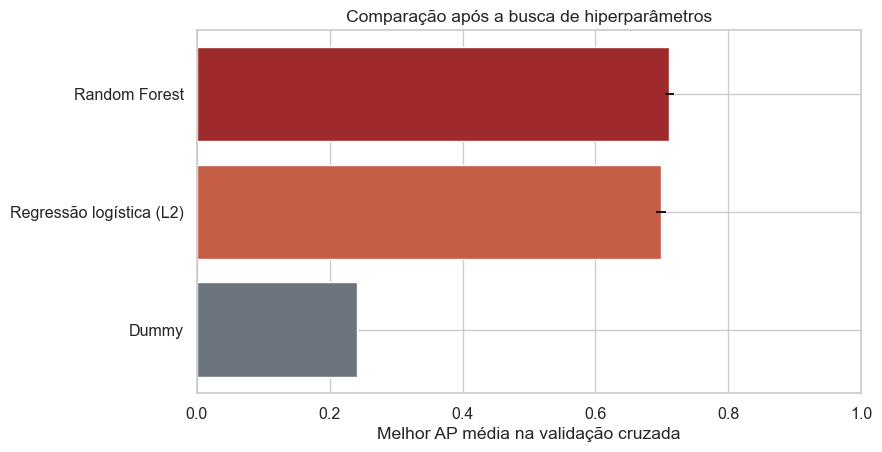

In [6]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)

# Dummy: referência que não aprende relações entre os atributos e a renda.
dummy = criar_pipeline(DummyClassifier(strategy='prior'))
scores_dummy = cross_validate(
    dummy, X_dev, y_dev, cv=cv,
    scoring={'AP': 'average_precision', 'ROC-AUC': 'roc_auc', 'F1': 'f1'},
    n_jobs=1, error_score='raise'
)

# Modelo linear regularizado. C controla a intensidade da regularização L2.
pipeline_logistica = criar_pipeline(
    LogisticRegression(
        solver='liblinear', max_iter=2000,
        random_state=SEMENTE
    )
)
grade_logistica = {
    'modelo__C': [0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    'modelo__class_weight': [None, 'balanced']
}
busca_logistica = GridSearchCV(
    pipeline_logistica, grade_logistica,
    scoring='average_precision', cv=cv, refit=True,
    n_jobs=1, error_score='raise'
)
busca_logistica.fit(X_dev, y_dev)

# Conjunto de árvores. A busca é aleatória para não deixar o notebook pesado demais.
pipeline_floresta = criar_pipeline(
    RandomForestClassifier(random_state=SEMENTE, n_jobs=-1)
)
espaco_floresta = {
    'modelo__n_estimators': [100, 150, 200, 250],
    'modelo__max_depth': [None, 12, 18, 24],
    'modelo__min_samples_leaf': [1, 3, 5, 8],
    'modelo__max_features': ['sqrt', 0.5],
    'modelo__class_weight': [None, 'balanced']
}
busca_floresta = RandomizedSearchCV(
    pipeline_floresta, espaco_floresta,
    n_iter=10, scoring='average_precision', cv=cv,
    refit=True, random_state=SEMENTE,
    n_jobs=1, error_score='raise'
)
busca_floresta.fit(X_dev, y_dev)

resultados_selecao = pd.DataFrame([
    {
        'Modelo': 'Dummy',
        'Melhor AP média': scores_dummy['test_AP'].mean(),
        'Desvio da AP': scores_dummy['test_AP'].std(),
        'Busca de hiperparâmetros': 'Não se aplica'
    },
    {
        'Modelo': 'Regressão logística (L2)',
        'Melhor AP média': busca_logistica.best_score_,
        'Desvio da AP': busca_logistica.cv_results_['std_test_score'][busca_logistica.best_index_],
        'Busca de hiperparâmetros': str(busca_logistica.best_params_)
    },
    {
        'Modelo': 'Random Forest',
        'Melhor AP média': busca_floresta.best_score_,
        'Desvio da AP': busca_floresta.cv_results_['std_test_score'][busca_floresta.best_index_],
        'Busca de hiperparâmetros': str(busca_floresta.best_params_)
    }
]).sort_values('Melhor AP média', ascending=False).reset_index(drop=True)

display(resultados_selecao.assign(
    **{
        'Melhor AP média': resultados_selecao['Melhor AP média'].round(3),
        'Desvio da AP': resultados_selecao['Desvio da AP'].round(3)
    }
))

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.barh(
    resultados_selecao['Modelo'][::-1],
    resultados_selecao['Melhor AP média'][::-1],
    xerr=resultados_selecao['Desvio da AP'][::-1],
    color=[COR_NEUTRA, COR_SECUNDARIA, COR_PRINCIPAL]
)
ax.set_xlabel('Melhor AP média na validação cruzada')
ax.set_title('Comparação após a busca de hiperparâmetros')
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()


In [7]:
melhor_nome_original = (
    'Regressão logística'
    if busca_logistica.best_score_ >= busca_floresta.best_score_
    else 'Random Forest'
)
melhor_busca_original = (
    busca_logistica if melhor_nome_original == 'Regressão logística'
    else busca_floresta
)

display(Markdown(
    f"**Leitura da comparação:** o melhor resultado entre os modelos que aprendem "
    f"com os dados foi o da **{melhor_nome_original}**, com AP média de "
    f"**{melhor_busca_original.best_score_:.3f}**. O Dummy ficou em "
    f"**{scores_dummy['test_AP'].mean():.3f}**. Como todos foram avaliados nas "
    "mesmas divisões, a comparação fica mais justa."
))


**Leitura da comparação:** o melhor resultado entre os modelos que aprendem com os dados foi o da **Random Forest**, com AP média de **0.711**. O Dummy ficou em **0.241**. Como todos foram avaliados nas mesmas divisões, a comparação fica mais justa.

## 5. Mudança proposta no pipeline

No pipeline da APS1, cada categoria recebia uma coluna no one-hot encoding. Algumas categorias, principalmente em `native.country`, aparecem poucas vezes. Isso pode criar colunas muito específicas e aumentar a chance de o modelo aprender detalhes do conjunto de desenvolvimento.

Como mudança, vamos **agrupar em uma mesma coluna as categorias que aparecem menos de 20 vezes**. O restante do tratamento será mantido. Para avaliar a mudança de forma justa, repetimos a busca de hiperparâmetros do melhor modelo da etapa anterior, usando a mesma AP e a mesma validação cruzada.


,Pipeline,AP média,Diferença para o original
0,Original da APS1,0.7114,0.0
1,Com agrupamento de categorias raras,0.7114,-0.0


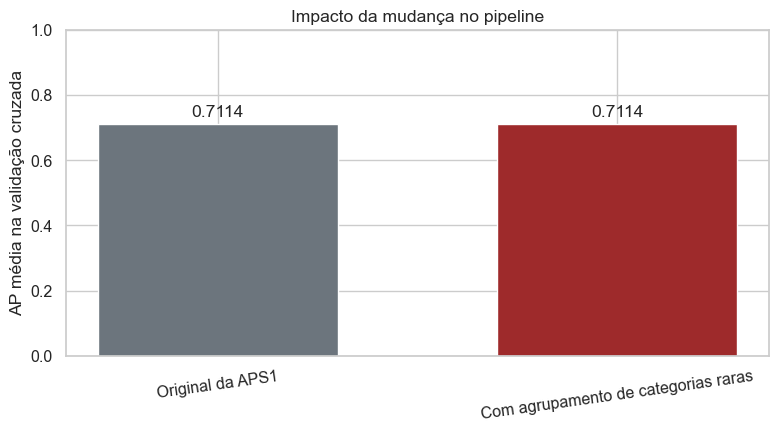

A mudança levou a uma AP média de **0.711**, contra **0.711** no pipeline original. Por isso, seguimos com **Pipeline original da APS1**. A decisão foi tomada somente com o conjunto de desenvolvimento.

Melhores parâmetros da versão final: {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 3, 'modelo__max_features': 'sqrt', 'modelo__max_depth': None, 'modelo__class_weight': None}


In [8]:
if melhor_nome_original == 'Regressão logística':
    estimador_mudanca = LogisticRegression(
        solver='liblinear', max_iter=2000,
        random_state=SEMENTE
    )
    espaco_mudanca = grade_logistica
else:
    estimador_mudanca = RandomForestClassifier(
        random_state=SEMENTE, n_jobs=-1
    )
    espaco_mudanca = espaco_floresta

busca_pipeline_mudado = RandomizedSearchCV(
    criar_pipeline(estimador_mudanca, agrupar_raras=True),
    param_distributions=espaco_mudanca,
    n_iter=8, scoring='average_precision', cv=cv,
    refit=True, random_state=SEMENTE,
    n_jobs=1, error_score='raise'
)
busca_pipeline_mudado.fit(X_dev, y_dev)

comparacao_pipeline = pd.DataFrame({
    'Pipeline': ['Original da APS1', 'Com agrupamento de categorias raras'],
    'AP média': [melhor_busca_original.best_score_, busca_pipeline_mudado.best_score_]
})
comparacao_pipeline['Diferença para o original'] = (
    comparacao_pipeline['AP média'] - melhor_busca_original.best_score_
)
display(comparacao_pipeline.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(
    comparacao_pipeline['Pipeline'], comparacao_pipeline['AP média'],
    color=[COR_NEUTRA, COR_PRINCIPAL], width=.6
)
ax.set_ylabel('AP média na validação cruzada')
ax.set_title('Impacto da mudança no pipeline')
ax.set_ylim(0, 1)
ax.bar_label(barras, fmt='%.4f', padding=3)
plt.xticks(rotation=8)
plt.tight_layout()
plt.show()

if busca_pipeline_mudado.best_score_ > melhor_busca_original.best_score_:
    VERSAO_FINAL = 'Pipeline com agrupamento de categorias raras'
    modelo_escolhido_dev = busca_pipeline_mudado.best_estimator_
    melhor_ap_cv = busca_pipeline_mudado.best_score_
    melhores_parametros_finais = busca_pipeline_mudado.best_params_
else:
    VERSAO_FINAL = 'Pipeline original da APS1'
    modelo_escolhido_dev = melhor_busca_original.best_estimator_
    melhor_ap_cv = melhor_busca_original.best_score_
    melhores_parametros_finais = melhor_busca_original.best_params_

display(Markdown(
    f"A mudança levou a uma AP média de **{busca_pipeline_mudado.best_score_:.3f}**, "
    f"contra **{melhor_busca_original.best_score_:.3f}** no pipeline original. "
    f"Por isso, seguimos com **{VERSAO_FINAL}**. A decisão foi tomada somente "
    "com o conjunto de desenvolvimento."
))
print('Melhores parâmetros da versão final:', melhores_parametros_finais)


## 6. Curva de aprendizado

A curva de aprendizado mostra o que acontece quando aumentamos a quantidade de exemplos usados no treinamento. Se treino e validação ainda estiverem melhorando no final da curva, mais dados podem ajudar. Se houver uma distância grande entre as duas curvas, o modelo pode estar se ajustando demais ao treino.


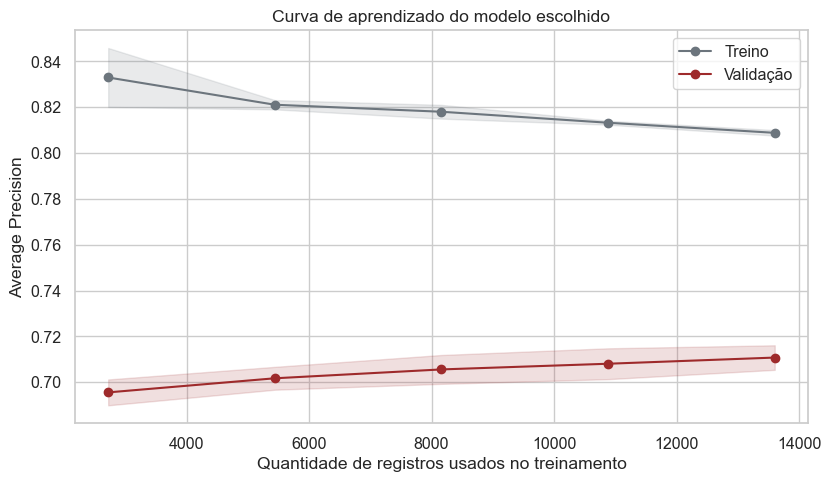

No maior tamanho testado, a AP média foi **0.809** no treino e **0.711** na validação. A diferença entre elas foi **0.098**. A curva permite observar se o modelo ainda ganhava estabilidade com o aumento da amostra.

In [9]:
tamanhos, scores_treino, scores_validacao = learning_curve(
    clone(modelo_escolhido_dev), X_dev, y_dev,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv, scoring='average_precision', n_jobs=1,
    shuffle=True, random_state=SEMENTE
)

media_treino = scores_treino.mean(axis=1)
desvio_treino = scores_treino.std(axis=1)
media_validacao = scores_validacao.mean(axis=1)
desvio_validacao = scores_validacao.std(axis=1)

plt.figure(figsize=(8.5, 5))
plt.plot(tamanhos, media_treino, marker='o', color=COR_NEUTRA, label='Treino')
plt.fill_between(tamanhos, media_treino-desvio_treino,
                 media_treino+desvio_treino, color=COR_NEUTRA, alpha=.15)
plt.plot(tamanhos, media_validacao, marker='o', color=COR_PRINCIPAL, label='Validação')
plt.fill_between(tamanhos, media_validacao-desvio_validacao,
                 media_validacao+desvio_validacao, color=COR_PRINCIPAL, alpha=.15)
plt.xlabel('Quantidade de registros usados no treinamento')
plt.ylabel('Average Precision')
plt.title('Curva de aprendizado do modelo escolhido')
plt.legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"No maior tamanho testado, a AP média foi **{media_treino[-1]:.3f}** no treino "
    f"e **{media_validacao[-1]:.3f}** na validação. A diferença entre elas foi "
    f"**{media_treino[-1]-media_validacao[-1]:.3f}**. A curva permite observar "
    "se o modelo ainda ganhava estabilidade com o aumento da amostra."
))


### Interpretação da curva de aprendizado

No maior tamanho de treinamento avaliado, a AP foi de 0,809 no treino e 0,711 na validação, uma diferença de 0,098. Essa distância sugere que ainda existe uma diferença relevante entre o desempenho nos dados utilizados para ajustar o modelo e nos dados de validação. Portanto, há espaço para melhorar sua capacidade de generalização. Ao mesmo tempo, a curva isoladamente não permite afirmar que mais dados resolveriam essa diferença, sendo necessário avaliar também a estabilidade dos resultados.


## 7. Escolha do limiar na validação

Depois de escolher o pipeline e os hiperparâmetros, usamos o conjunto de validação para escolher o limiar que maximiza o F1. O valor padrão de 0,50 continua sendo apresentado para comparação. Em uma aplicação real, o limiar deveria levar em conta o custo dos falsos positivos e falsos negativos.


,Limiar,Acurácia,Precisão,Recall,F1,ROC-AUC,AP
"Padrão (0,50)",0.5000,0.8320,0.6926,0.5432,0.6089,0.8861,0.7055
Otimizado no F1,0.3274,0.8151,0.5876,0.7785,0.6697,0.8861,0.7055


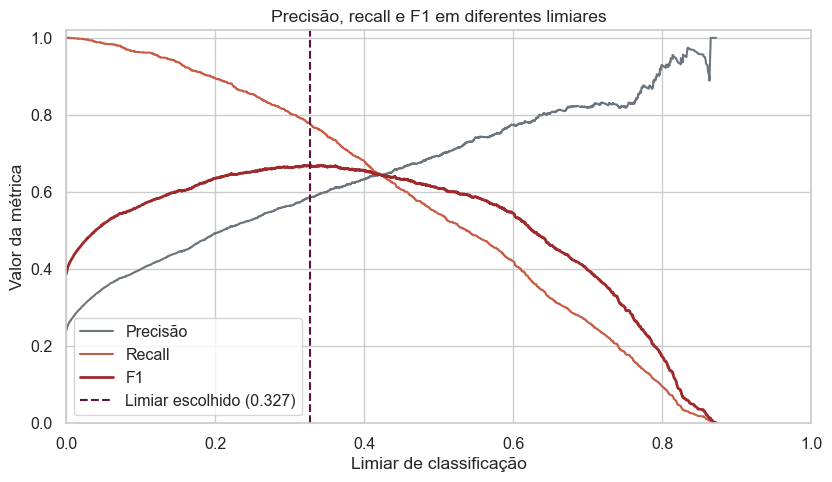

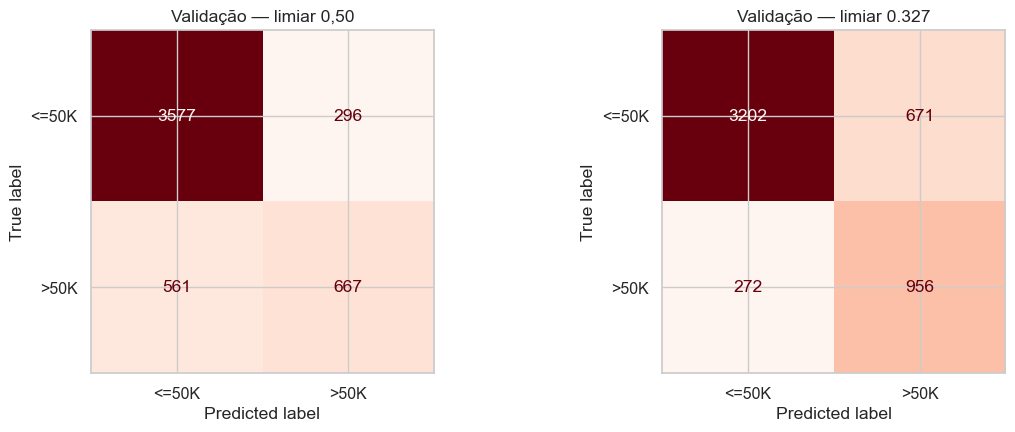

In [10]:
prob_val = modelo_escolhido_dev.predict_proba(X_val)[:, 1]
prec_curva, rec_curva, limiares_pr = precision_recall_curve(y_val, prob_val)
f1_por_limiar = (
    2 * prec_curva[:-1] * rec_curva[:-1] /
    np.maximum(prec_curva[:-1] + rec_curva[:-1], 1e-12)
)
melhor_idx = int(np.argmax(f1_por_limiar))
limiar_otimo = float(limiares_pr[melhor_idx])

def resumir_metricas(y_real, y_previsto, probabilidades):
    return {
        'Acurácia': accuracy_score(y_real, y_previsto),
        'Precisão': precision_score(y_real, y_previsto, zero_division=0),
        'Recall': recall_score(y_real, y_previsto, zero_division=0),
        'F1': f1_score(y_real, y_previsto, zero_division=0),
        'ROC-AUC': roc_auc_score(y_real, probabilidades),
        'AP': average_precision_score(y_real, probabilidades)
    }

prev_val_05 = (prob_val >= 0.50).astype(int)
prev_val_otimo = (prob_val >= limiar_otimo).astype(int)
comparacao_limiares = pd.DataFrame([
    {'Limiar': 0.50, **resumir_metricas(y_val, prev_val_05, prob_val)},
    {'Limiar': limiar_otimo, **resumir_metricas(y_val, prev_val_otimo, prob_val)}
], index=['Padrão (0,50)', 'Otimizado no F1'])
display(comparacao_limiares.round(4))

# O gráfico mostra a troca entre precisão e recall quando o limiar é alterado.
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(limiares_pr, prec_curva[:-1], color=COR_NEUTRA, label='Precisão')
ax.plot(limiares_pr, rec_curva[:-1], color=COR_SECUNDARIA, label='Recall')
ax.plot(limiares_pr, f1_por_limiar, color=COR_PRINCIPAL, lw=2, label='F1')
ax.axvline(
    limiar_otimo, color=COR_DESTAQUE, linestyle='--',
    label=f'Limiar escolhido ({limiar_otimo:.3f})'
)
ax.set_xlabel('Limiar de classificação')
ax.set_ylabel('Valor da métrica')
ax.set_title('Precisão, recall e F1 em diferentes limiares')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_val, prev_val_05, display_labels=['<=50K', '>50K'],
    cmap='Reds', colorbar=False, ax=axes[0]
)
axes[0].set_title('Validação — limiar 0,50')
ConfusionMatrixDisplay.from_predictions(
    y_val, prev_val_otimo, display_labels=['<=50K', '>50K'],
    cmap='Reds', colorbar=False, ax=axes[1]
)
axes[1].set_title(f'Validação — limiar {limiar_otimo:.3f}')
plt.tight_layout()
plt.show()


In [11]:
mat_05 = confusion_matrix(y_val, prev_val_05)
mat_novo = confusion_matrix(y_val, prev_val_otimo)
display(Markdown(
    f"O F1 passou de **{f1_score(y_val, prev_val_05):.3f}** para "
    f"**{f1_score(y_val, prev_val_otimo):.3f}** com o limiar de "
    f"**{limiar_otimo:.3f}**. Os falsos negativos mudaram de "
    f"**{mat_05[1,0]}** para **{mat_novo[1,0]}**, enquanto os falsos "
    f"positivos foram de **{mat_05[0,1]}** para **{mat_novo[0,1]}**."
))


O F1 passou de **0.609** para **0.670** com o limiar de **0.327**. Os falsos negativos mudaram de **561** para **272**, enquanto os falsos positivos foram de **296** para **671**.

### O que a escolha do limiar nos mostra

Na validação, reduzir o limiar de 0,50 para aproximadamente 0,327 aumentou o F1 de 0,609 para 0,670. O modelo passou a identificar mais registros da classe `>50K`, reduzindo os falsos negativos de 561 para 272. Em contrapartida, os falsos positivos aumentaram de 296 para 671. Esse resultado mostra que não existe um limiar ideal para todas as situações: a escolha depende de quais erros são mais importantes na aplicação do modelo.


## 8. Avaliação final no teste

Todas as escolhas foram encerradas antes desta etapa. Agora treinamos novamente o pipeline escolhido usando os 25.505 registros do treino original e abrimos o teste reservado. Depois de observar o teste, não mudaremos mais o modelo.


,Acurácia,Precisão,Recall,F1,ROC-AUC,AP
Configuração,,,,,,
Limiar escolhido na validação,0.8118,0.5819,0.7752,0.6648,0.8842,0.703
"Limiar padrão (0,50)",0.8328,0.6969,0.5407,0.6090,0.8842,0.703


              precision    recall  f1-score   support

       <=50K      0.920     0.823     0.869      4842
        >50K      0.582     0.775     0.665      1535

    accuracy                          0.812      6377
   macro avg      0.751     0.799     0.767      6377
weighted avg      0.839     0.812     0.820      6377

Verdadeiros negativos=3987, falsos positivos=855, falsos negativos=345, verdadeiros positivos=1190


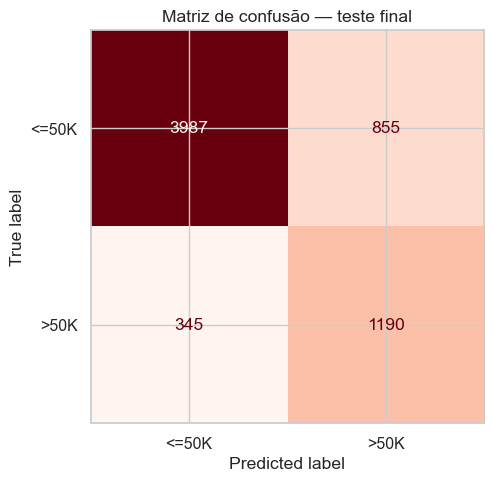

In [12]:
modelo_final = clone(modelo_escolhido_dev)
modelo_final.fit(X_train_modelo, y_train)

prob_test = modelo_final.predict_proba(X_test_modelo)[:, 1]
prev_test_final = (prob_test >= limiar_otimo).astype(int)
prev_test_05 = (prob_test >= 0.50).astype(int)

resultado_teste = pd.DataFrame([
    {'Configuração': 'Limiar escolhido na validação',
     **resumir_metricas(y_test, prev_test_final, prob_test)},
    {'Configuração': 'Limiar padrão (0,50)',
     **resumir_metricas(y_test, prev_test_05, prob_test)}
]).set_index('Configuração')
display(resultado_teste.round(4))

print(classification_report(
    y_test, prev_test_final,
    target_names=['<=50K', '>50K'], digits=3, zero_division=0
))

matriz_teste = confusion_matrix(y_test, prev_test_final)
tn, fp, fn, tp = matriz_teste.ravel()
print(f'Verdadeiros negativos={tn}, falsos positivos={fp}, '
      f'falsos negativos={fn}, verdadeiros positivos={tp}')

fig, ax = plt.subplots(figsize=(6.3, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_teste,
    display_labels=['<=50K', '>50K']
).plot(cmap='Reds', ax=ax, colorbar=False, values_format='d')
ax.set_title('Matriz de confusão — teste final')
plt.tight_layout()
plt.show()


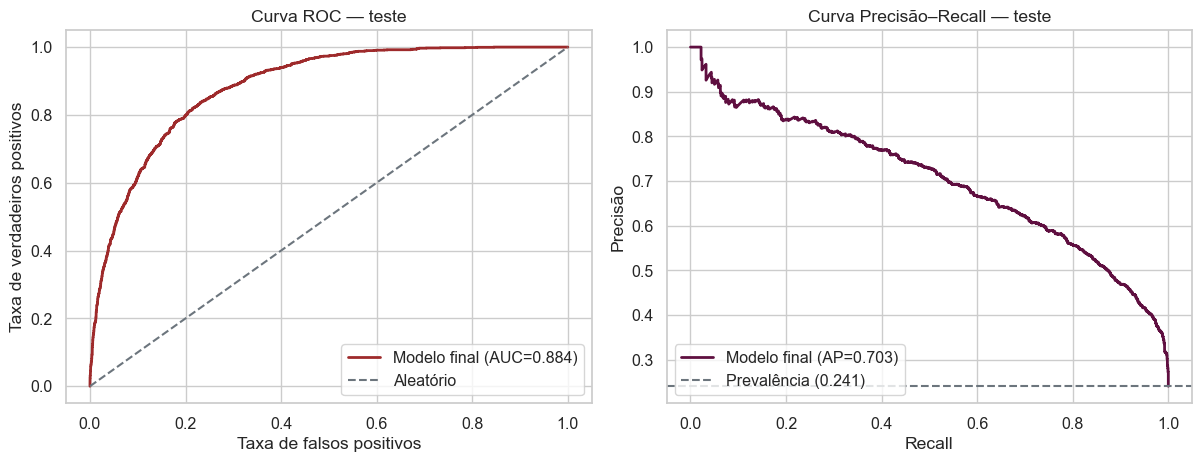

No teste, a acurácia foi **0.812**, a precisão **0.582**, o recall **0.775** e o F1 **0.665**. A ROC-AUC foi **0.884** e a AP **0.703**. A matriz teve **855 falsos positivos** e **345 falsos negativos**.

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

fpr, tpr, _ = roc_curve(y_test, prob_test)
auc_final = roc_auc_score(y_test, prob_test)
axes[0].plot(fpr, tpr, color=COR_PRINCIPAL, lw=2,
             label=f'Modelo final (AUC={auc_final:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color=COR_NEUTRA, label='Aleatório')
axes[0].set(xlabel='Taxa de falsos positivos',
            ylabel='Taxa de verdadeiros positivos',
            title='Curva ROC — teste')
axes[0].legend(loc='lower right')

prec_teste, rec_teste, _ = precision_recall_curve(y_test, prob_test)
ap_final = average_precision_score(y_test, prob_test)
axes[1].plot(rec_teste, prec_teste, color=COR_DESTAQUE, lw=2,
             label=f'Modelo final (AP={ap_final:.3f})')
axes[1].axhline(y_test.mean(), color=COR_NEUTRA, ls='--',
                label=f'Prevalência ({y_test.mean():.3f})')
axes[1].set(xlabel='Recall', ylabel='Precisão',
            title='Curva Precisão–Recall — teste')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

metricas_finais = resumir_metricas(y_test, prev_test_final, prob_test)
display(Markdown(
    f"No teste, a acurácia foi **{metricas_finais['Acurácia']:.3f}**, a precisão "
    f"**{metricas_finais['Precisão']:.3f}**, o recall **{metricas_finais['Recall']:.3f}** "
    f"e o F1 **{metricas_finais['F1']:.3f}**. A ROC-AUC foi "
    f"**{metricas_finais['ROC-AUC']:.3f}** e a AP **{metricas_finais['AP']:.3f}**. "
    f"A matriz teve **{fp} falsos positivos** e **{fn} falsos negativos**."
))


## 9. Interpretando a regressão logística

Mesmo que ela não seja o modelo final, a regressão logística ajuda a enxergar a direção das associações aprendidas. Coeficientes positivos aumentam a chance prevista de `>50K`, enquanto coeficientes negativos reduzem essa chance. Abaixo mostramos os três coeficientes de maior magnitude absoluta.

Como as variáveis numéricas foram escaladas e as categóricas passaram por one-hot encoding, a leitura é feita sobre as colunas transformadas. Os coeficientes descrevem o modelo e não representam efeitos causais.


,Variável transformada,Coeficiente,Magnitude
0,categoricas__workclass_Ausente,-1.7622,1.7622
1,categoricas__marital.status_Married-civ-spouse,1.2196,1.2196
2,categoricas__relationship_Own-child,-1.1781,1.1781


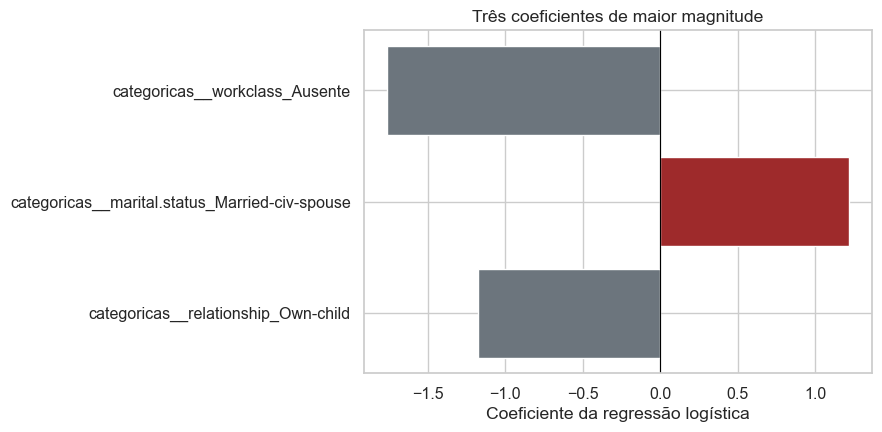

**Leitura dos três coeficientes:** `categoricas__workclass_Ausente` reduziu a chance prevista de `>50K` (coeficiente -1.762); `categoricas__marital.status_Married-civ-spouse` aumentou a chance prevista de `>50K` (coeficiente 1.220); `categoricas__relationship_Own-child` reduziu a chance prevista de `>50K` (coeficiente -1.178). A comparação vale dentro deste pipeline e não prova que essas características causem uma renda maior ou menor.

In [14]:
modelo_logistica = busca_logistica.best_estimator_
nomes_logistica = modelo_logistica.named_steps['preprocessamento'].get_feature_names_out()
coeficientes = modelo_logistica.named_steps['modelo'].coef_[0]

tabela_coeficientes = pd.DataFrame({
    'Variável transformada': nomes_logistica,
    'Coeficiente': coeficientes,
    'Magnitude': np.abs(coeficientes)
}).sort_values('Magnitude', ascending=False).reset_index(drop=True)

top3_coeficientes = tabela_coeficientes.head(3).copy()
display(top3_coeficientes.round(4))

cores_coef = [COR_PRINCIPAL if c > 0 else COR_NEUTRA
              for c in top3_coeficientes['Coeficiente']]
plt.figure(figsize=(9, 4.5))
plt.barh(top3_coeficientes['Variável transformada'][::-1],
         top3_coeficientes['Coeficiente'][::-1],
         color=cores_coef[::-1])
plt.axvline(0, color='black', linewidth=.8)
plt.xlabel('Coeficiente da regressão logística')
plt.title('Três coeficientes de maior magnitude')
plt.tight_layout()
plt.show()

frases_coef = []
for _, linha in top3_coeficientes.iterrows():
    direcao = 'aumentou' if linha['Coeficiente'] > 0 else 'reduziu'
    frases_coef.append(
        f"`{linha['Variável transformada']}` {direcao} a chance prevista de `>50K` "
        f"(coeficiente {linha['Coeficiente']:.3f})"
    )
display(Markdown(
    "**Leitura dos três coeficientes:** " + "; ".join(frases_coef) + ". "
    "A comparação vale dentro deste pipeline e não prova que essas características "
    "causem uma renda maior ou menor."
))


## 10. Importância das variáveis na Random Forest

Para o conjunto de árvores, usamos importância por permutação no conjunto de validação. Embaralhamos uma variável original por vez e medimos quanto a AP diminui. Uma queda maior indica que a floresta dependia mais daquela informação.


,Atributo,Queda média na AP,Desvio
0,education.num,0.1004,0.0169
1,marital.status,0.0824,0.0073
2,occupation,0.0799,0.0213


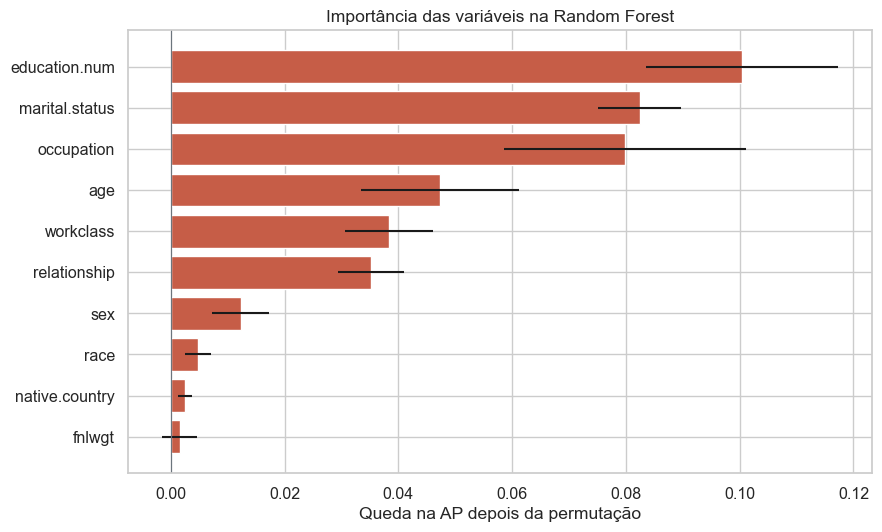

As três maiores quedas ocorreram em `education.num` (0.100), `marital.status` (0.082), `occupation` (0.080). Isso significa que essas variáveis foram as mais úteis para a floresta nesta validação. Se duas colunas trazem informações parecidas, a importância pode ficar dividida entre elas.

In [15]:
modelo_floresta = busca_floresta.best_estimator_
amostra_importancia = X_val.sample(n=min(1500, len(X_val)), random_state=SEMENTE)
y_importancia = y_val.loc[amostra_importancia.index]

resultado_permutacao = permutation_importance(
    modelo_floresta, amostra_importancia, y_importancia,
    scoring='average_precision', n_repeats=5,
    random_state=SEMENTE, n_jobs=1
)
ranking_importancia = pd.DataFrame({
    'Atributo': X_val.columns,
    'Queda média na AP': resultado_permutacao.importances_mean,
    'Desvio': resultado_permutacao.importances_std
}).sort_values('Queda média na AP', ascending=False).reset_index(drop=True)

top3_floresta = ranking_importancia.head(3).copy()
display(top3_floresta.round(4))

ordem = ranking_importancia.sort_values('Queda média na AP')
plt.figure(figsize=(9, 5.5))
plt.barh(ordem['Atributo'], ordem['Queda média na AP'],
         xerr=ordem['Desvio'], color=COR_SECUNDARIA)
plt.axvline(0, color=COR_NEUTRA, linewidth=.8)
plt.xlabel('Queda na AP depois da permutação')
plt.title('Importância das variáveis na Random Forest')
plt.tight_layout()
plt.show()

texto_top3 = ', '.join(
    f"`{linha['Atributo']}` ({linha['Queda média na AP']:.3f})"
    for _, linha in top3_floresta.iterrows()
)
display(Markdown(
    f"As três maiores quedas ocorreram em {texto_top3}. Isso significa que essas "
    "variáveis foram as mais úteis para a floresta nesta validação. Se duas colunas "
    "trazem informações parecidas, a importância pode ficar dividida entre elas."
))


## 11. Explicabilidade do modelo final com SHAP

O SHAP distribui a diferença entre a previsão do modelo e um valor de referência entre as variáveis usadas naquela previsão. Primeiro fazemos uma leitura global e depois olhamos três casos individuais: um verdadeiro positivo, um falso positivo e um falso negativo.

Como o pipeline transforma as variáveis antes da classificação, os gráficos mostram as colunas depois do pré-processamento. Valores SHAP positivos empurram a previsão para `>50K`; valores negativos empurram para `<=50K`.


 40%|========            | 243/606 [00:11<00:16]       

 44%|=========           | 266/606 [00:12<00:15]       

 48%|==========          | 290/606 [00:13<00:14]       

 52%|==========          | 314/606 [00:14<00:13]       

 56%|===========         | 339/606 [00:15<00:11]       

 60%|============        | 365/606 [00:16<00:10]       

... (5 outputs left out)

 85%|=================   | 517/606 [00:22<00:03]       

 89%|==================  | 542/606 [00:23<00:02]       

 94%|=================== | 569/606 [00:24<00:01]       

 98%|===================| 594/606 [00:25<00:00]       

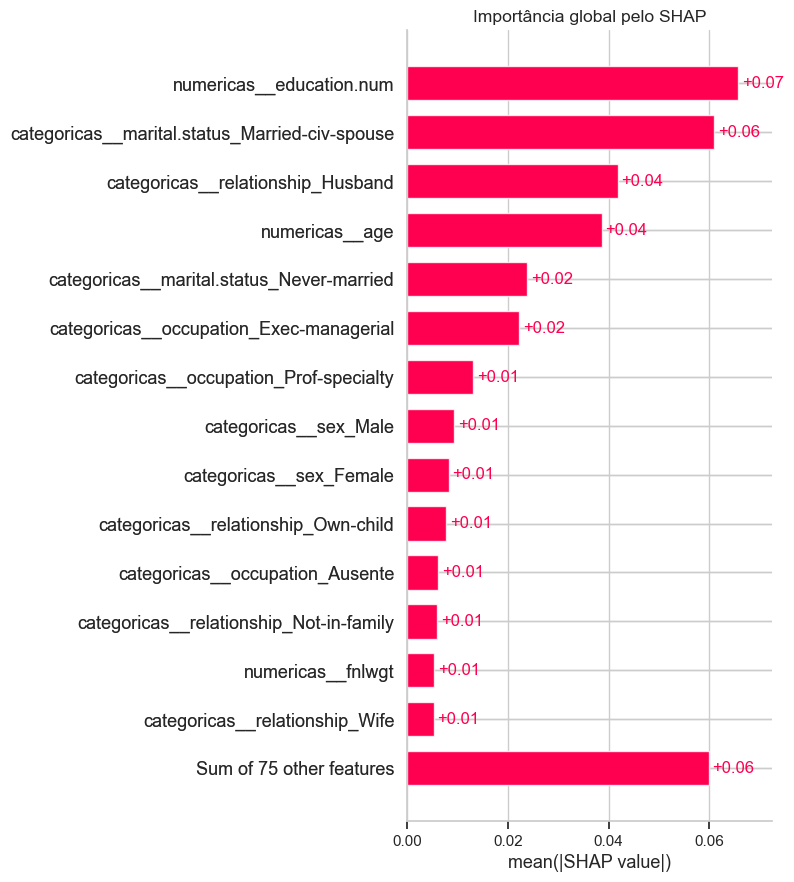

In [16]:
preprocessamento_final = modelo_final.named_steps['preprocessamento']
classificador_final = modelo_final.named_steps['modelo']
nomes_shap = preprocessamento_final.get_feature_names_out()

# Selecionamos três tipos de caso e completamos com uma amostra para a visão global.
tipos_casos = {
    'Verdadeiro positivo': (y_test.to_numpy() == 1) & (prev_test_final == 1),
    'Falso positivo': (y_test.to_numpy() == 0) & (prev_test_final == 1),
    'Falso negativo': (y_test.to_numpy() == 1) & (prev_test_final == 0)
}
indices_individuais = []
rotulos_individuais = []
for nome_caso, mascara in tipos_casos.items():
    posicoes = np.flatnonzero(mascara)
    if len(posicoes):
        indices_individuais.append(X_test_modelo.index[posicoes[0]])
        rotulos_individuais.append(nome_caso)

amostra_global = X_test_modelo.sample(
    n=min(300, len(X_test_modelo)), random_state=SEMENTE
)
X_shap = pd.concat([
    amostra_global,
    X_test_modelo.loc[indices_individuais]
]).loc[lambda d: ~d.index.duplicated(keep='first')]

X_shap_transformado = preprocessamento_final.transform(X_shap)
if hasattr(X_shap_transformado, 'toarray'):
    X_shap_transformado = X_shap_transformado.toarray()

background = X_shap_transformado[:min(100, len(X_shap_transformado))]
explicador = shap.Explainer(
    classificador_final, background, feature_names=nomes_shap
)
explicacoes = explicador(X_shap_transformado)

# Alguns classificadores retornam uma dimensão para cada classe.
if explicacoes.values.ndim == 3:
    explicacoes_positivas = explicacoes[:, :, 1]
else:
    explicacoes_positivas = explicacoes

shap.plots.bar(explicacoes_positivas, max_display=15, show=False)
plt.title('Importância global pelo SHAP')
plt.tight_layout()
plt.show()


Verdadeiro positivo | classe real: >50K | previsão: >50K | probabilidade de >50K: 0.770


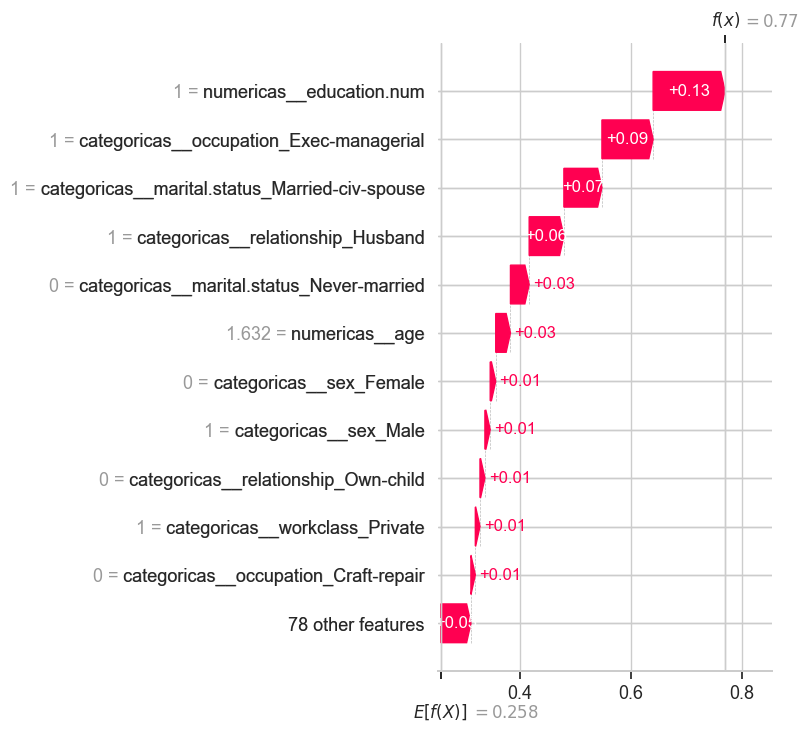

Neste **verdadeiro positivo**, as três maiores contribuições foram `numericas__education.num` (para >50K), `categoricas__occupation_Exec-managerial` (para >50K), `categoricas__marital.status_Married-civ-spouse` (para >50K).

Falso positivo | classe real: <=50K | previsão: >50K | probabilidade de >50K: 0.542


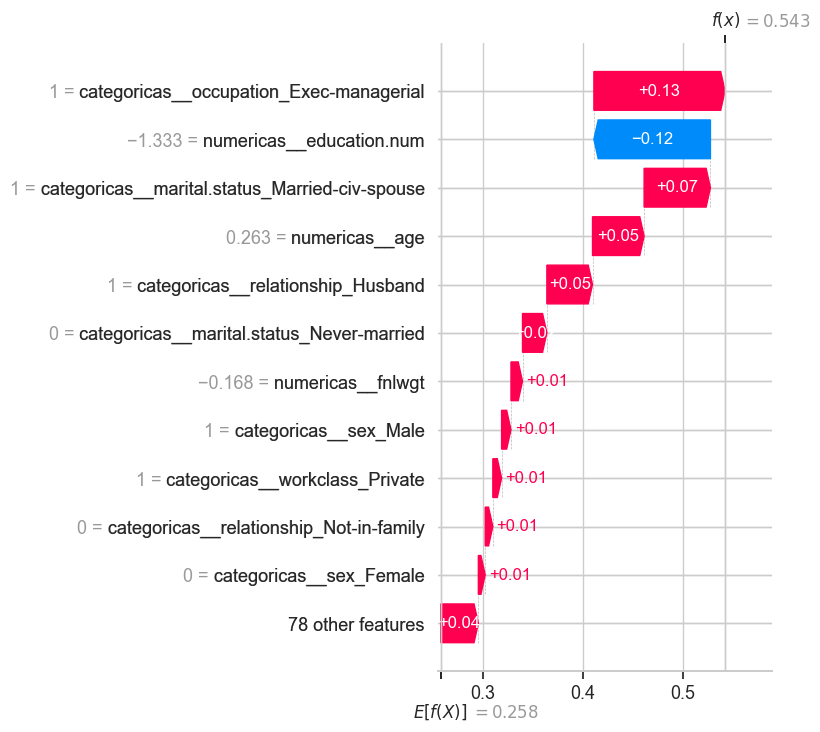

Neste **falso positivo**, as três maiores contribuições foram `categoricas__occupation_Exec-managerial` (para >50K), `numericas__education.num` (para <=50K), `categoricas__marital.status_Married-civ-spouse` (para >50K).

Falso negativo | classe real: >50K | previsão: <=50K | probabilidade de >50K: 0.256


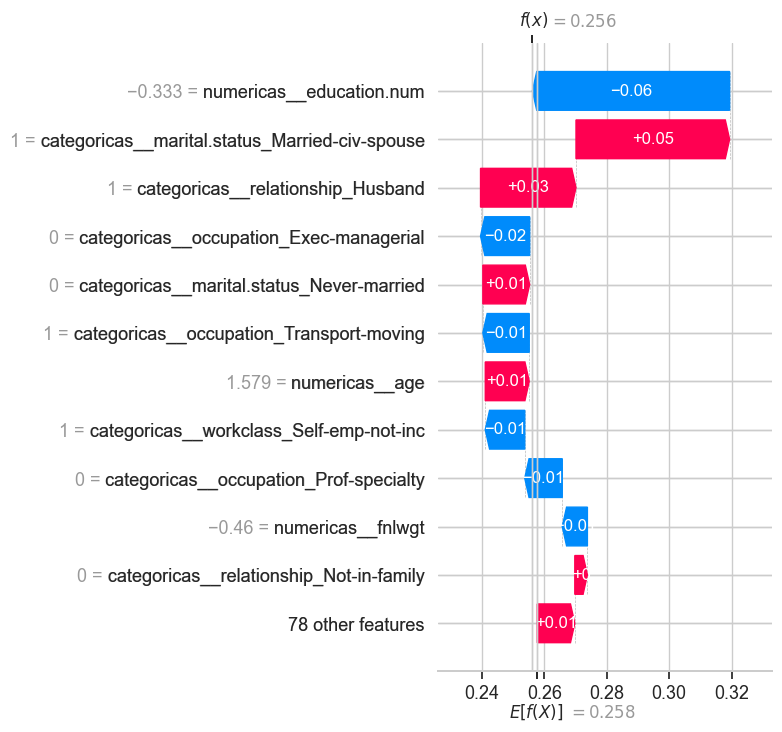

Neste **falso negativo**, as três maiores contribuições foram `numericas__education.num` (para <=50K), `categoricas__marital.status_Married-civ-spouse` (para >50K), `categoricas__relationship_Husband` (para >50K).

In [17]:
for indice, nome_caso in zip(indices_individuais, rotulos_individuais):
    posicao = X_shap.index.get_loc(indice)
    probabilidade = modelo_final.predict_proba(X_test_modelo.loc[[indice]])[0, 1]
    real = '>50K' if y_test.loc[indice] == 1 else '<=50K'
    previsto = '>50K' if prev_test_final[X_test_modelo.index.get_loc(indice)] == 1 else '<=50K'

    print(f'{nome_caso} | classe real: {real} | previsão: {previsto} '
          f'| probabilidade de >50K: {probabilidade:.3f}')
    shap.plots.waterfall(
        explicacoes_positivas[posicao], max_display=12, show=False
    )
    plt.tight_layout()
    plt.show()

    valores = explicacoes_positivas.values[posicao]
    tres_posicoes = np.argsort(np.abs(valores))[-3:][::-1]
    leituras = []
    for j in tres_posicoes:
        direcao = 'para >50K' if valores[j] > 0 else 'para <=50K'
        leituras.append(f"`{nomes_shap[j]}` ({direcao})")
    display(Markdown(
        f"Neste **{nome_caso.lower()}**, as três maiores contribuições foram "
        + ', '.join(leituras) + "."
    ))


### Cuidados na leitura do SHAP

O gráfico global mostra quais variáveis mais alteraram as previsões na amostra explicada. Já os gráficos individuais ajudam a entender por que o modelo chegou a uma previsão específica. Mesmo assim, SHAP explica o comportamento do modelo, e não uma relação de causa e efeito na renda (LUNDBERG; LEE, 2017; MOLNAR, 2022).


### Comparando as previsões individuais

Os três casos mostram que uma mesma característica pode contribuir para aumentar ou reduzir a previsão, dependendo dos demais atributos do registro. No falso positivo, por exemplo, características associadas pelo modelo à faixa `>50K` contribuíram para uma classificação incorreta. Isso ajuda a entender por que o modelo pode errar mesmo quando identifica padrões relevantes nos dados. As explicações SHAP descrevem a contribuição das variáveis para a previsão, mas não demonstram causalidade.


## 12. Discussão crítica

### Limitações novas do modelo

1. **O limiar depende de um objetivo escolhido por nós.** Usamos o maior F1, que dá o mesmo peso para precisão e recall. Em uma aplicação real, falsos positivos e falsos negativos podem ter custos diferentes. Portanto, o limiar precisaria ser definido com as pessoas responsáveis pelo uso do modelo, e não apenas por uma métrica estatística.

2. **As probabilidades não foram calibradas.** Um registro com probabilidade prevista de 0,70 não representa necessariamente 70% de chance real de ter renda `>50K`. Antes de usar as probabilidades diretamente, seria necessário avaliar curvas de calibração e, se preciso, aplicar uma técnica como `CalibratedClassifierCV` (SCIKIT-LEARN, 2026).

### Limitações novas dos dados

1. **O limite de 50 mil dólares perdeu significado ao longo do tempo.** A base Adult deriva do Census Income e usa um corte nominal de renda. Esse valor não foi corrigido pela inflação, então a mesma classe teria outro significado econômico em anos diferentes.

2. **A base representa um contexto histórico e geográfico específico.** Relações aprendidas em dados censitários dos Estados Unidos não devem ser transferidas automaticamente para o Brasil, para anos atuais ou para outras populações. Mudanças no mercado de trabalho podem produzir desvio de dados e de conceito.

### Ações para operação e manutenção

1. **Monitoramento contínuo.** Acompanhar AP, precisão, recall, calibração, proporção das classes e desempenho por grupos ao longo do tempo. Uma queda consistente ou mudança forte na distribuição deve acionar nova validação e possível retreinamento.

2. **Versionamento e revisão humana.** Registrar a versão dos dados, do código, dos hiperparâmetros e do limiar. Antes de cada atualização, repetir os testes e documentar as mudanças. Como a base envolve atributos sensíveis, o modelo não deveria tomar decisões individuais automaticamente.


## 13. Conclusão

Retomamos o pipeline da APS1 e comparamos uma referência simples, um modelo linear regularizado e um conjunto de árvores. A escolha foi feita com Average Precision e validação cruzada, sem consultar o teste. Também testamos uma mudança no one-hot encoding, construímos uma curva de aprendizado e escolhemos o limiar usando um conjunto de validação separado.

Na interpretação, usamos os coeficientes da regressão logística, a importância por permutação da Random Forest e o SHAP para observar tanto o comportamento global quanto três previsões individuais. Essas análises ajudam a entender o modelo, mas não transformam associações em relações causais.

Os números abaixo são preenchidos pela execução do notebook e resumem o resultado final.


In [18]:
m = resumir_metricas(y_test, prev_test_final, prob_test)
resumo_final = f"""
### Resultado resumido

O modelo escolhido foi **{melhor_nome_original}**, usando **{VERSAO_FINAL.lower()}**. A AP média na seleção ficou em **{melhor_ap_cv:.3f}** e o limiar escolhido na validação foi **{limiar_otimo:.3f}**.

No teste, obtivemos **acurácia de {m['Acurácia']:.3f}**, **precisão de {m['Precisão']:.3f}**, **recall de {m['Recall']:.3f}**, **F1 de {m['F1']:.3f}**, **ROC-AUC de {m['ROC-AUC']:.3f}** e **AP de {m['AP']:.3f}**. A matriz de confusão apresentou **{fp} falsos positivos** e **{fn} falsos negativos**.

O resultado ficou acima do Dummy em AP, mostrando que as variáveis carregam informação útil para separar as faixas de renda. Mesmo assim, ainda existe sobreposição entre as classes. Por isso, o modelo deve ser entendido como um experimento acadêmico com essa base, e não como uma ferramenta pronta para decisões sobre pessoas.
"""
display(Markdown(resumo_final))



### Resultado resumido

O modelo escolhido foi **Random Forest**, usando **pipeline original da aps1**. A AP média na seleção ficou em **0.711** e o limiar escolhido na validação foi **0.327**.

No teste, obtivemos **acurácia de 0.812**, **precisão de 0.582**, **recall de 0.775**, **F1 de 0.665**, **ROC-AUC de 0.884** e **AP de 0.703**. A matriz de confusão apresentou **855 falsos positivos** e **345 falsos negativos**.

O resultado ficou acima do Dummy em AP, mostrando que as variáveis carregam informação útil para separar as faixas de renda. Mesmo assim, ainda existe sobreposição entre as classes. Por isso, o modelo deve ser entendido como um experimento acadêmico com essa base, e não como uma ferramenta pronta para decisões sobre pessoas.


## 14. Referências

- BRECK, E. et al. **The ML Test Score: A Rubric for ML Production Readiness and Technical Debt Reduction.** IEEE Big Data, 2017. Disponível em: https://research.google/pubs/the-ml-test-score-a-rubric-for-ml-production-readiness-and-technical-debt-reduction/.
- GÉRON, A. **Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow.** 3. ed. Sebastopol: O'Reilly Media, 2022.
- INSPER. **Machine Learning — Projeto 2026.2.** Disponível em: https://insper.github.io/ML/pt/2026.2/project/.
- KAGGLE. **Adult Income Census.** Disponível em: https://www.kaggle.com/datasets/anaghakp/adult-income-census.
- LUNDBERG, S. M.; LEE, S.-I. **A Unified Approach to Interpreting Model Predictions.** Advances in Neural Information Processing Systems, 2017. Disponível em: https://arxiv.org/abs/1705.07874.
- MOLNAR, C. **Interpretable Machine Learning.** 2. ed., 2022. Disponível em: https://christophm.github.io/interpretable-ml-book/.
- SCIKIT-LEARN. **Calibration curves.** Disponível em: https://scikit-learn.org/stable/modules/calibration.html.
- SCIKIT-LEARN. **Cross-validation: evaluating estimator performance.** Disponível em: https://scikit-learn.org/stable/modules/cross_validation.html.
- SCIKIT-LEARN. **Learning curve.** Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html.
- SCIKIT-LEARN. **Pipelines and composite estimators.** Disponível em: https://scikit-learn.org/stable/modules/compose.html.
- UCI MACHINE LEARNING REPOSITORY. **Adult Data Set.** Disponível em: https://archive.ics.uci.edu/dataset/2/adult.
